# Semana 1: carga y reporte de Fast_Food_Restaurants

En este notebook se construye un flujo completo de trabajo:

1. Configurar la ruta del proyecto para importar las clases reutilizables.
2. Cargar `Fast_Food_Restaurants` desde Hugging Face.
3. Obtener un `DataFrame` de pandas y revisar su estructura.
4. Generar un reporte en pantalla y guardarlo en un archivo `.txt`.

Ejecuta las celdas en orden. Si el dataset requiere autenticación, inicia sesión previamente con `hf auth login`.

## 1. Preparar el entorno e importar la clase de carga

El notebook puede ejecutarse desde distintas carpetas. Por eso se buscan los directorios padres hasta encontrar `src/clases_po` y se agrega `src` a `sys.path`. Así se puede importar `HFDatasetLoader` sin instalar el proyecto como paquete.

In [18]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader

## 2. Configurar el dataset y la salida

`dataset_name` identifica el repositorio en Hugging Face y `split="train"` indica la división que se descargará. El parámetro `filename` hace que el `DataFrame` también se guarde como CSV en `src/sincronicas/datos/` cuando el notebook se ejecuta desde esa carpeta.

In [19]:
loader = HFDatasetLoader(
    dataset_name="Bizwhiznetwork/pizza_sales",
    split="train",
    filename="datos/pizza_sales.csv",
)


## 3. Descargar el dataset y crear el DataFrame

El método `load()` descarga el dataset, lo convierte a `pandas.DataFrame` y lo asigna a la variable `df`. La expresión `df.head()` muestra las primeras filas para comprobar que la carga fue exitosa.

In [20]:
df = loader.load()
df.head()

,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
0,1.0,1.0,hawaiian_m,1.0,1/1/2015,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2.0,2.0,classic_dlx_m,1.0,1/1/2015,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza
2,3.0,2.0,five_cheese_l,1.0,1/1/2015,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza
3,4.0,2.0,ital_supr_l,1.0,1/1/2015,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza
4,5.0,2.0,mexicana_m,1.0,1/1/2015,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza


In [21]:
df.shape

(48620, 12)

## 4. Revisar la estructura del DataFrame

Esta celda realiza una revisión inicial: cuenta filas y columnas y muestra el tipo de cada columna junto con información de memoria y valores no nulos. Esta inspección ayuda a detectar problemas antes de analizar los datos.

In [22]:
print(f"Filas: {len(df)}")
print(f"Columnas: {len(df.columns)}")
df.info()

Filas: 48620
Columnas: 12
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pizza_id           48620 non-null  float64
 1   order_id           48620 non-null  float64
 2   pizza_name_id      48620 non-null  object 
 3   quantity           48620 non-null  float64
 4   order_date         48620 non-null  object 
 5   order_time         48620 non-null  object 
 6   unit_price         48620 non-null  float64
 7   total_price        48620 non-null  float64
 8   pizza_size         48620 non-null  object 
 9   pizza_category     48620 non-null  object 
 10  pizza_ingredients  48620 non-null  object 
 11  pizza_name         48620 non-null  object 
dtypes: float64(5), object(7)
memory usage: 4.5+ MB


## 1.1 Preparar el entorno e importar las clases

El notebook puede ejecutarse desde distintas carpetas. Por eso se buscan los directorios padres hasta encontrar `src/clases_po` y se agrega `src` a `sys.path`. Así se pueden importar las clases sin instalar el proyecto como paquete.

In [23]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader, Reportes
from clases_po import PreprocesadorPizzas, LLMNvidia, EnriquecedorPizzeria
from clases_po import AnalisisBase, GraficosBase, AnalisisPizzeria, GraficosPizzeria

import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

## 1.2 Configurar el dataset y la salida

`dataset_name` identifica el repositorio en Hugging Face y `split="train"` indica la división que se descargará. El parámetro `filename` hace que el `DataFrame` también se guarde como CSV en `src/sincronicas/datos/` cuando el notebook se ejecuta desde esa carpeta.

In [24]:
loader = HFDatasetLoader(
    dataset_name="Bizwhiznetwork/pizza_sales",
    split="train",
    filename="datos/pizza_sales.csv",
)

---
# PARTE 2 · Preprocesamiento y estandarización (clase `PreprocesadorPizzas`)

El Excel de clase trabaja con las **primeras 1.700 líneas** (1 al 13 de enero de 2015; el día 13 está incompleto). `filas_clase=1700` toma exactamente ese corte para que los resultados sean comparables. Con `filas_clase=None` se usaría todo el dataset (todo 2015).

## 2.1 Diagnóstico de tipos (hoja **Tipos**, sección A)

Equivale a `ESTEXTO`, `ESNUMERO`, `CONTARA` y `CONTAR` por columna.

In [25]:
pre = PreprocesadorPizzas(filas_clase=48620)

df_base = pre.recortar(df)
pre.diagnosticar(df_base)

,columna,tipo_actual,ejemplo,no_vacíos (CONTARA),convertibles_a_número,¿es número? (ESNUMERO)
0,pizza_id,float64,1.0,48620,48620,True
1,order_id,float64,1.0,48620,48620,True
2,pizza_name_id,object,hawaiian_m,48620,0,False
3,quantity,float64,1.0,48620,48620,True
4,order_date,object,1/1/2015,48620,0,False
5,order_time,object,11:38:36,48620,0,False
6,unit_price,float64,13.25,48620,48620,True
7,total_price,float64,13.25,48620,48620,True
8,pizza_size,object,M,48620,0,False
9,pizza_category,object,Classic,48620,0,False


**Lectura:** fecha y hora llegan como **texto** (y la fecha mezcla `1/1/2015` con `13-01-2015`), los identificadores como decimales (`1.0`), y tamaño y categoría como texto libre.

## 2.2 Diccionario de columnas (hoja **Tipos**, sección B)

In [26]:
pre.diccionario()

,columna,qué significa,tipo de variable,tipo en pandas
0,pizza_id,Número de la línea,Cualitativa (identificador),Int64 (entero)
1,order_id,Número del pedido,Cualitativa (identificador),Int64 (entero)
2,pizza_name_id,Código de pizza y tamaño,Cualitativa nominal,string
3,quantity,Pizzas en la línea,Cuantitativa discreta,int64
4,order_date,Fecha del pedido (día/mes/año),Cuantitativa (tiempo),datetime64
5,order_time,Hora del pedido,Cuantitativa (tiempo),time (hh:mm:ss)
6,unit_price,Precio de una pizza,Cuantitativa continua,"float64 (moneda, 2 dec.)"
7,total_price,Cantidad × precio unitario,Cuantitativa continua,"float64 (moneda, 2 dec.)"
8,pizza_size,Tamaño,Cualitativa ordinal (S < M < L < XL),category ordenada
9,pizza_category,Categoría,Cualitativa nominal,category


## 2.3 Convertir tipos y agregar columnas calculadas (hojas **Tipos** D-E y **Datos**)

| Excel | Método de la clase |
|---|---|
| `VALOR.NUMERO`, `SUSTITUIR` + `FECHA`, `HORANUMERO`, formato Texto | `convertir_tipos()` |
| `total_calculado`, `verificación`, `día_semana`, `hora`, `nuevo_pedido` | `agregar_columnas_calculadas()` |
| Los dos pasos seguidos | `procesar()` |

In [27]:
datos = pre.procesar(df)
datos.head()

,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name,fecha_hora,total_calculado,verificacion,dia_semana,hora,nuevo_pedido
0,1,1,hawaiian_m,1,2015-01-01,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza,2015-01-01 11:38:36,13.25,OK,jueves,11,1
1,2,2,classic_dlx_m,1,2015-01-01,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza,2015-01-01 11:57:40,16.00,OK,jueves,11,1
2,3,2,five_cheese_l,1,2015-01-01,11:57:40,18.50,18.50,L,Veggie,"Mozzarella Cheese, Provolone Cheese, Smoked Go...",The Five Cheese Pizza,2015-01-01 11:57:40,18.50,OK,jueves,11,0
3,4,2,ital_supr_l,1,2015-01-01,11:57:40,20.75,20.75,L,Supreme,"Calabrese Salami, Capocollo, Tomatoes, Red Oni...",The Italian Supreme Pizza,2015-01-01 11:57:40,20.75,OK,jueves,11,0
4,5,2,mexicana_m,1,2015-01-01,11:57:40,16.00,16.00,M,Veggie,"Tomatoes, Red Peppers, Jalapeno Peppers, Red O...",The Mexicana Pizza,2015-01-01 11:57:40,16.00,OK,jueves,11,0


In [28]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   pizza_id           48620 non-null  Int64         
 1   order_id           48620 non-null  Int64         
 2   pizza_name_id      48620 non-null  string        
 3   quantity           48620 non-null  int64         
 4   order_date         48620 non-null  datetime64[ns]
 5   order_time         48620 non-null  object        
 6   unit_price         48620 non-null  float64       
 7   total_price        48620 non-null  float64       
 8   pizza_size         48620 non-null  category      
 9   pizza_category     48620 non-null  category      
 10  pizza_ingredients  48620 non-null  string        
 11  pizza_name         48620 non-null  string        
 12  fecha_hora         48620 non-null  datetime64[ns]
 13  total_calculado    48620 non-null  float64       
 14  verifi

## 2.4 Validaciones de calidad

In [29]:
pre.validar(datos)

✔ Sin valores nulos tras convertir 
✔ Sin filas duplicadas 
✔ total_price = quantity × unit_price (0 filas a revisar)
✔ Fechas en orden cronológico según order_id 

Comparación con el Excel de clase:
✘ Ventas totales   = $28,663.15 → $817,860.05
✘ Pizzas vendidas  = 48,620 → 49,574
✔ Líneas de venta  = 48,620 → 48,620
✘ Pedidos          = 755 → 21,350

Rango de fechas: 01/01/2015 a 31/12/2015 (358 días; el último tiene 171 líneas)


False

---
# PARTE 3 · Análisis del Excel con los datos originales (sin enriquecer)

Antes de enriquecer,  tal como viene: **una sola pizzería, 1 al 13 de enero de 2015, 1.700 líneas**. Así los resultados se pueden comparar uno a uno con las hojas del Excel.

- `AB = AnalisisBase(datos, dias_incompletos=["2015-01-13"])` calcula las tablas. El 13/01 está incompleto (50 líneas): cuenta en los totales, pero se excluye de los promedios por día de la semana para no castigar al martes.
- `GB = GraficosBase(AB)` dibuja los 9 gráficos del Excel y el dashboard.

In [35]:
AB = AnalisisBase(datos, pizza_elegida="The Pepperoni Pizza", dias_incompletos=["2015-01-13"])
GB = GraficosBase(AB)
print("Periodo analizado:", AB.periodo())

Periodo analizado: 01/01/2015 a 31/12/2015 (358 días)


## 3.1 Fórmulas básicas (hoja **Fórmulas**)

Cada fórmula del Excel con su equivalente en pandas y el resultado: operaciones con la fila 185 (3 Spicy Italian), funciones de resumen, valores únicos y una condición.

In [36]:
AB.formulas_basicas(fila_excel=185)

,#,qué quiero saber,fórmula en Excel,equivalente en pandas,resultado
0,1,Multiplicar: total de la línea,=Datos!D185*Datos!G185,V.quantity[i] * V.unit_price[i],62.25
1,2,Dividir: precio de cada pizza,=Datos!H185/Datos!D185,V.total_price[i] / V.quantity[i],20.75
2,3,Sumar: pizzas en dos líneas,=Datos!D185+Datos!D186,V.quantity[i] + V.quantity[i+1],4.0
3,4,Restar: precio más alto − más bajo,=MAX(G)-MIN(G),V.unit_price.max() - V.unit_price.min(),26.2
4,5,Redondear el precio promedio,=REDONDEAR(PROMEDIO(G);2),"round(V.unit_price.mean(), 2)",16.49
5,6,Ventas totales,=SUMA(H),V.total_price.sum(),817860.05
6,7,Pizzas vendidas,=SUMA(D),V.quantity.sum(),49574.0
7,8,Líneas con número,=CONTAR(H),V.total_price.count(),48620.0
8,9,Líneas con nombre de pizza,=CONTARA(L),V.pizza_name.notna().sum(),48620.0
9,10,Celdas vacías en la categoría,=CONTAR.BLANCO(J),V.pizza_category.isna().sum(),0.0


## 3.2 Resumen del negocio (hoja **Descriptiva**, sección A)

In [37]:
## 3.2 Resumen del negocio (hoja **Descriptiva**, sección A)

In [38]:
display(AB.estilo(AB.resumen_total()))
print("Ojo: el último día (13/01) está incompleto, así que la venta promedio por día subestima un poco.")

,Empresa
Ventas totales,"817,860.05"
Pizzas vendidas,"49,574.00"
Líneas de pedido,"48,620.00"
Pedidos,"21,350.00"
Ticket promedio,38.31
Pizzas por pedido,2.32
Precio promedio por pizza,16.50
Días con ventas,358.00
Venta promedio por día,"2,284.53"


Ojo: el último día (13/01) está incompleto, así que la venta promedio por día subestima un poco.


## 3.3 Medidas de las variables cuantitativas

In [39]:
display(AB.medidas_variables().round(3))
print(AB.lectura_media_mediana())

,quantity,unit_price,total_price,valor_pedido
n (datos),48620.000,48620.000,48620.000,21350.000
Suma,49574.000,801944.700,817860.050,817860.050
Media,1.020,16.494,16.821,38.307
Mediana,1.000,16.500,16.500,32.500
Moda,1.000,20.750,20.750,20.750
Mínimo,1.000,9.750,9.750,9.750
Máximo,4.000,35.950,83.000,444.200
Rango,3.000,26.200,73.250,434.450
Desviación estándar,0.143,3.622,4.437,30.648
Coef. de variación,0.140,0.220,0.264,0.800


Lectura: en total_price la media ($16.82) es mayor que la mediana ($16.50): unas pocas líneas con varias pizzas jalan el promedio hacia arriba (sesgo a la derecha).


## 3.4 Frecuencias por tamaño y por categoría (hoja **Descriptiva**, secciones C y D) · Gráficos 3, 4 y 5

Por tamaño (variable ordinal: S < M < L < XL)


,líneas,% líneas,% acumulado,pizzas,ventas,% ventas,precio_unit_promedio
S,"14,137",29.1%,29.1%,"14,403","$178,076.50",21.8%,$12.36
M,"15,385",31.6%,60.7%,"15,635","$249,382.25",30.5%,$15.95
L,"18,526",38.1%,98.8%,"18,956","$375,318.70",45.9%,$19.80
XL,544,1.1%,99.9%,552,"$14,076.00",1.7%,$25.50
XXL,28,0.1%,100.0%,28,"$1,006.60",0.1%,$35.95
Total,"48,620",100.0%,—,"49,574","$817,860.05",100.0%,$16.49


Por categoría (variable nominal)


,líneas,% líneas,% acumulado,pizzas,ventas,% ventas,precio_unit_promedio
Classic,"14,579",30.0%,30.0%,"14,888","$220,053.10",26.9%,$14.80
Supreme,"11,777",24.2%,54.2%,"11,987","$208,197.00",25.5%,$17.36
Veggie,"11,449",23.5%,77.8%,"11,649","$193,690.45",23.7%,$16.61
Chicken,"10,815",22.2%,100.0%,"11,050","$195,919.50",24.0%,$17.71
Total,"48,620",100.0%,—,"49,574","$817,860.05",100.0%,$16.49


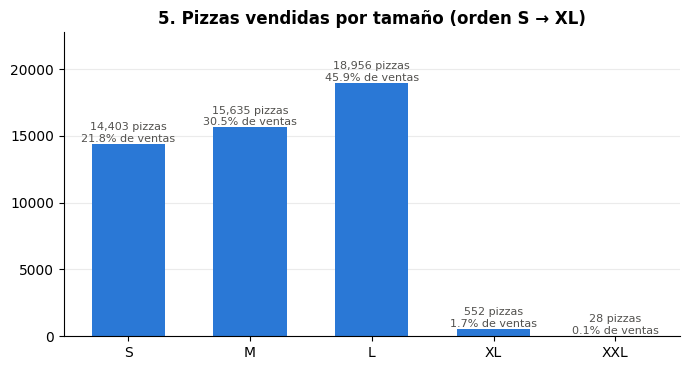

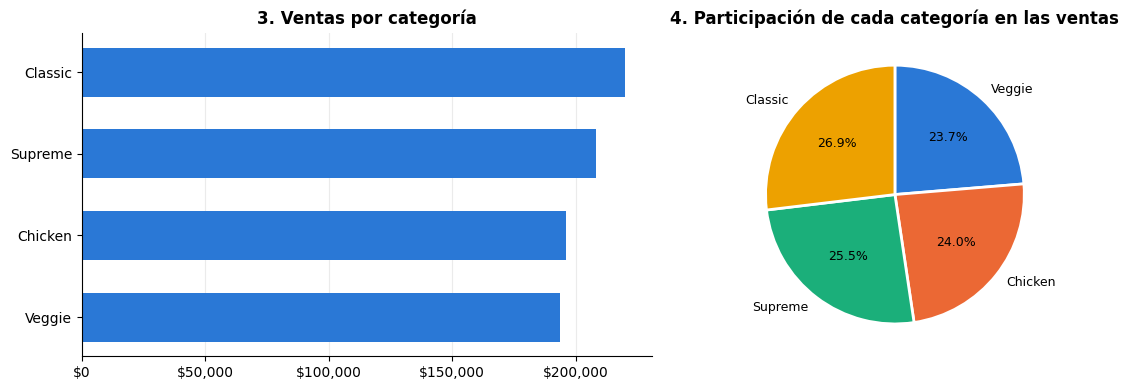

In [40]:
print("Por tamaño (variable ordinal: S < M < L < XL)")
display(AB.estilo(AB.frecuencias("pizza_size")))
print("Por categoría (variable nominal)")
display(AB.estilo(AB.frecuencias("pizza_category")))
GB.tamanos()
GB.categorias()

## 3.5 Distribución de `total_price`

,líneas,% líneas
total_price,,
$9 a $12,"2,271",4.7%
$12 a $15,"13,454",27.7%
$15 a $18,"16,007",32.9%
$18 a $21,"14,749",30.3%
$21 a $24,687,1.4%
$24 a $27,764,1.6%
$27 o más,688,1.4%


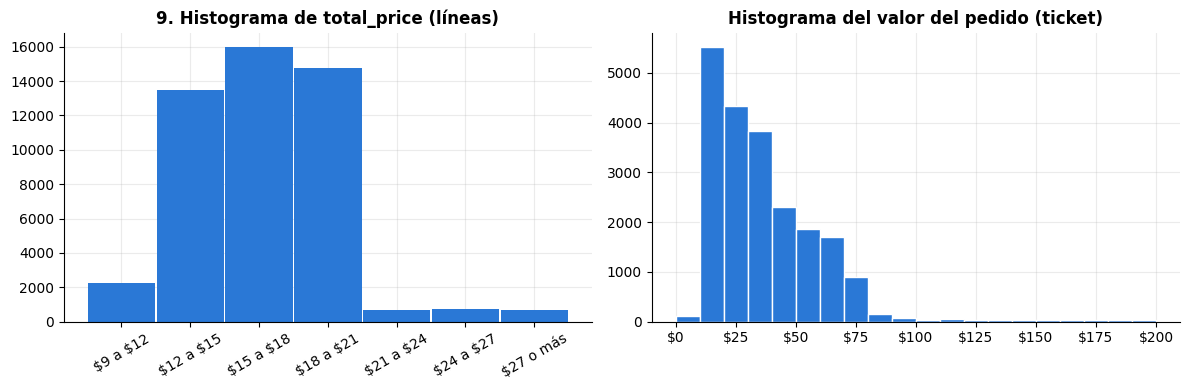

In [41]:
display(AB.estilo(AB.distribucion_precio()))
GB.histogramas()

## 3.6 Ventas por día y pizza elegida (hoja **Relaciones**, sección A) · Gráficos 1 y 2

Para cambiar la pizza (como la lista desplegable del Excel): `AB.pizza_elegida = "The Hawaiian Pizza"`.

,order_date,día,líneas,pizzas,pedidos,ventas,ticket promedio,% ventas,ventas pizza elegida
0,01/01/2015,jueves,161,162,69,"$2,713.85",$39.33,0.3%,$77.75
1,02/01/2015,viernes,160,165,67,"$2,731.90",$40.77,0.3%,$150.00
2,03/01/2015,sábado,154,158,66,"$2,662.40",$40.34,0.3%,$102.75
3,04/01/2015,domingo,106,106,52,"$1,755.45",$33.76,0.2%,$47.25
4,05/01/2015,lunes,121,125,54,"$2,065.95",$38.26,0.3%,$72.25
5,06/01/2015,martes,144,147,64,"$2,428.95",$37.95,0.3%,$102.75
6,07/01/2015,miércoles,133,138,58,"$2,202.20",$37.97,0.3%,$161.25
7,08/01/2015,jueves,171,173,72,"$2,838.35",$39.42,0.3%,$118.00
8,09/01/2015,viernes,123,127,62,"$2,127.35",$34.31,0.3%,$108.25
9,10/01/2015,sábado,145,146,65,"$2,463.95",$37.91,0.3%,$98.50


Día con más ventas: 27/11/2015 (viernes) → $4,422.45
Día con menos ventas (sin el último día, que está incompleto): 22/03/2015 (domingo) → $1,259.25
The Pepperoni Pizza: ventas $30,161.75; su mejor día 15/05/2015


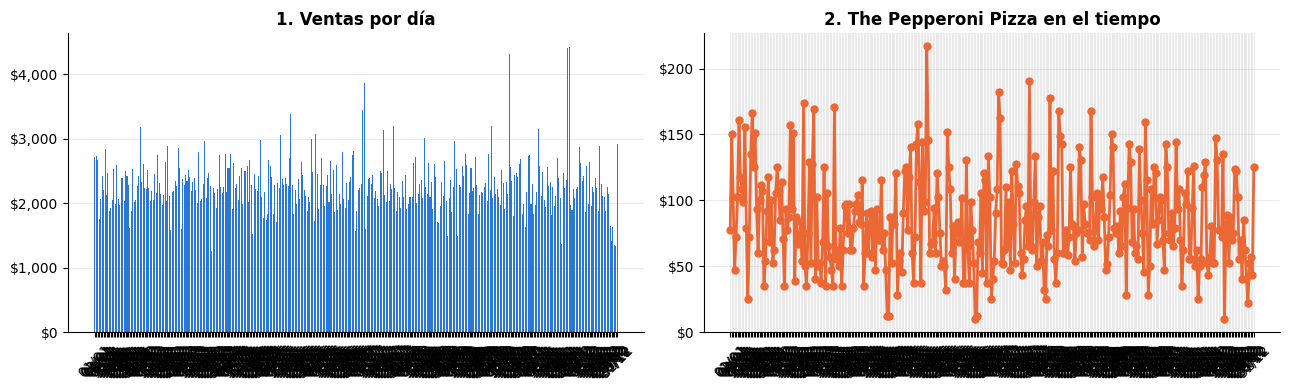

In [42]:
display(AB.estilo(AB.ventas_por_dia().reset_index().assign(order_date=lambda x: x["order_date"].dt.strftime("%d/%m/%Y"))))
print(AB.lectura_dias(excluir_ultimo_incompleto=True))
GB.ventas_por_dia()

Venta promedio por día de la semana (sin el 13/01 incompleto; en 12 días cada día aparece 1 o 2 veces)


,días en el periodo,ventas,venta promedio por día
dia_semana,,,
lunes,48,"$107,329.55","$2,236.03"
martes,51,"$112,084.20","$2,197.73"
miércoles,52,"$114,408.40","$2,200.16"
jueves,52,"$123,528.50","$2,375.55"
viernes,50,"$136,073.90","$2,721.48"
sábado,52,"$123,182.40","$2,368.89"
domingo,52,"$99,203.50","$1,907.76"


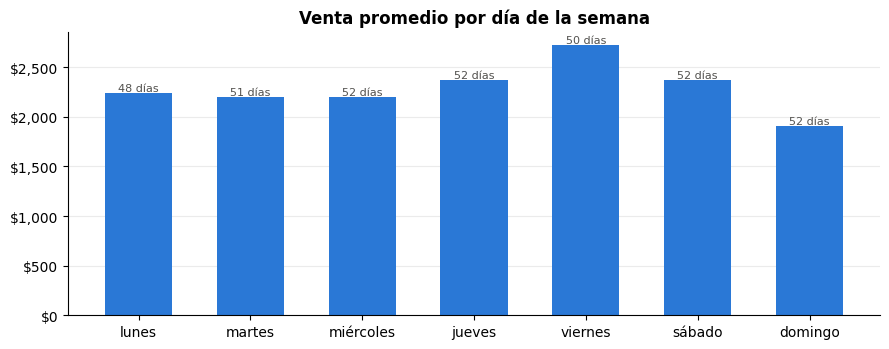

In [43]:
print("Venta promedio por día de la semana (sin el 13/01 incompleto; en 12 días cada día aparece 1 o 2 veces)")
display(AB.estilo(AB.dia_semana_resumen()))
GB.dia_semana()

## 3.7 Dos categorías a la vez: categoría × tamaño (hoja **Relaciones**, sección B) · Gráfico 6

,ventas S,ventas M,ventas L,ventas XL,ventas XXL,ventas Total
pizza_category,,,,,,
Classic,"$69,870.25","$60,581.75","$74,518.50","$14,076.00","$1,006.60","$220,053.10"
Supreme,"$47,463.50","$66,475.00","$94,258.50",$0.00,$0.00,"$208,197.00"
Veggie,"$32,386.75","$57,101.00","$104,202.70",$0.00,$0.00,"$193,690.45"
Chicken,"$28,356.00","$65,224.50","$102,339.00",$0.00,$0.00,"$195,919.50"
Total,"$178,076.50","$249,382.25","$375,318.70","$14,076.00","$1,006.60","$817,860.05"


pizza_size,S,M,L,XL,XXL,Total
pizza_category,,,,,,
Classic,5975,4045,3987,544,28,14579
Supreme,3323,3977,4477,0,0,11777
Veggie,2634,3552,5263,0,0,11449
Chicken,2205,3811,4799,0,0,10815
Total,14137,15385,18526,544,28,48620


Lectura: la combinación que más vende es Veggie L ($104,202.70).


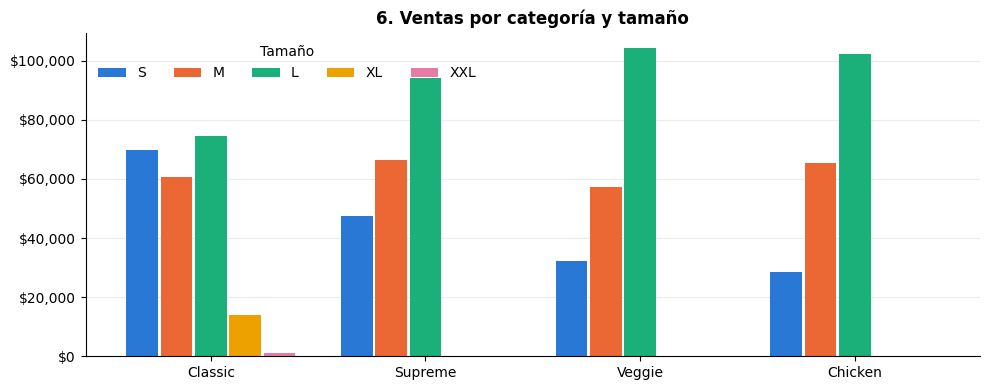

In [44]:
display(AB.estilo(AB.categoria_x_tamano("ventas")))
display(AB.categoria_x_tamano("lineas"))
print(AB.combinacion_lider())
GB.categoria_tamano()

## 3.8 Tres condiciones: un día, una categoría y un tamaño

In [45]:
pd.DataFrame({
    "08/01 · Veggie · L": AB.consulta(fecha="2015-01-08", categoria="Veggie", tamano="L"),
    "05/01 · Chicken · M": AB.consulta(fecha="2015-01-05", categoria="Chicken", tamano="M"),
    "13/01 · Classic · XL": AB.consulta(fecha="2015-01-13", categoria="Classic", tamano="XL"),
})

,08/01 · Veggie · L,05/01 · Chicken · M,13/01 · Classic · XL
Ventas,460.35,318.25,76.5
Pizzas,24.00,19.00,3.0
Líneas,24.00,16.00,3.0
Precio promedio,19.18,16.75,25.5


## 3.9 Ventas por hora

,líneas,ventas,% ventas
hora,,,
9,4,$83.00,0.0%
10,17,$303.65,0.0%
11,"2,672","$44,935.80",5.5%
12,"6,543","$111,877.90",13.7%
13,"6,203","$106,065.70",13.0%
14,"3,521","$59,201.40",7.2%
15,"3,170","$52,992.30",6.5%
16,"4,185","$70,055.40",8.6%
17,"5,143","$86,237.45",10.5%


Hora pico: 12:00


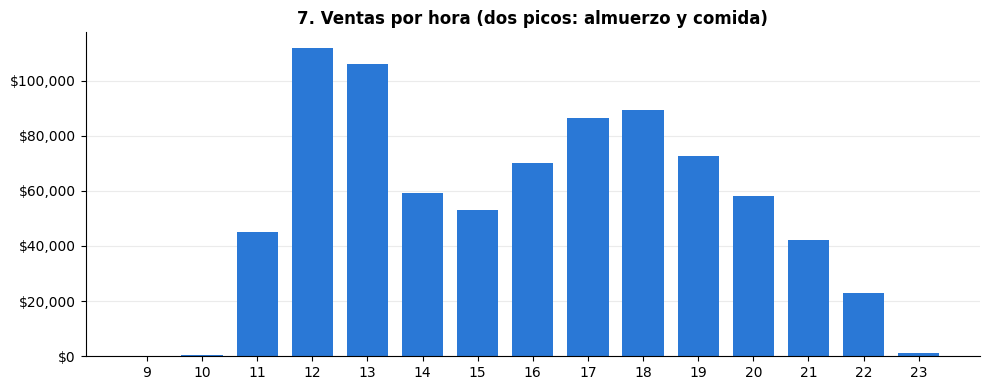

In [46]:
display(AB.estilo(AB.ventas_por_hora()))
print(f"Hora pico: {AB.ventas_por_hora()['ventas'].idxmax()}:00")
GB.ventas_hora()

## 3.10 Ranking de pizzas por ventas

,posición,categoría,pizzas,ventas,% ventas,% acumulado
pizza_name,,,,,,
The Thai Chicken Pizza,1,Chicken,"2,371","$43,434.25",5.3%,5.3%
The Barbecue Chicken Pizza,2,Chicken,"2,432","$42,768.00",5.2%,10.5%
The California Chicken Pizza,3,Chicken,"2,370","$41,409.50",5.1%,15.6%
The Classic Deluxe Pizza,4,Classic,"2,453","$38,180.50",4.7%,20.3%
The Spicy Italian Pizza,5,Supreme,"1,924","$34,831.25",4.3%,24.5%
The Southwest Chicken Pizza,6,Chicken,"1,917","$34,705.75",4.2%,28.8%
The Italian Supreme Pizza,7,Supreme,"1,884","$33,476.75",4.1%,32.9%
The Hawaiian Pizza,8,Classic,"2,422","$32,273.25",3.9%,36.8%
The Four Cheese Pizza,9,Veggie,"1,902","$32,265.70",3.9%,40.8%


Pareto: 22 de 32 pizzas generan el 80 % de las ventas.


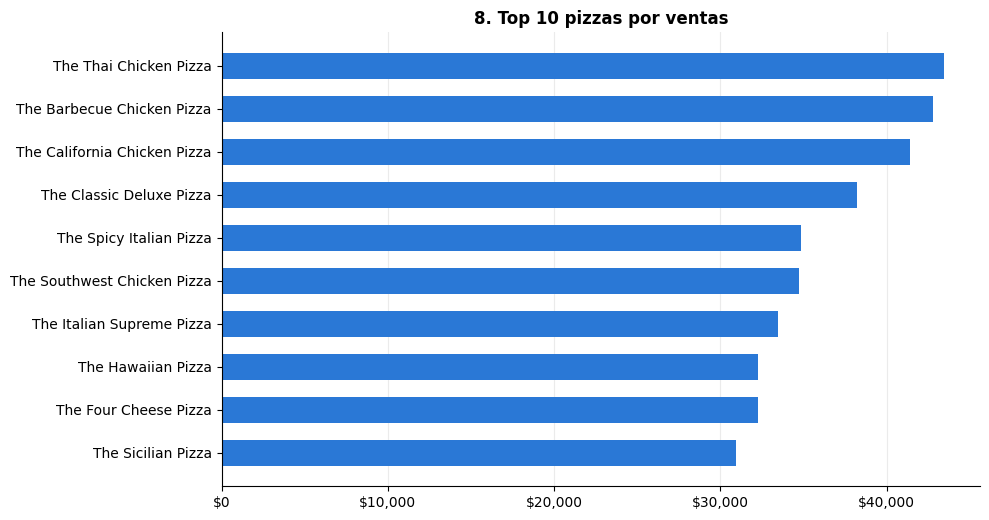

In [47]:
ranking_base = AB.ranking_pizzas()
display(AB.estilo(ranking_base))
print(f"Pareto: {AB.pizzas_para_80()} de {len(ranking_base)} pizzas generan el 80 % de las ventas.")
GB.top_pizzas(10)

## 3.11 Tabla dinámica

In [48]:
print("Filtro día_semana: - all -")
display(AB.estilo(AB.tabla_dinamica()))
print("Filtro día_semana: sábado")
AB.estilo(AB.tabla_dinamica(dia_semana="sábado"))

Filtro día_semana: - all -


,suma S,suma M,suma L,suma XL,suma XXL,suma Total
pizza_category,,,,,,
Classic,"$69,870.25","$60,581.75","$74,518.50","$14,076.00","$1,006.60","$220,053.10"
Supreme,"$47,463.50","$66,475.00","$94,258.50",$0.00,$0.00,"$208,197.00"
Veggie,"$32,386.75","$57,101.00","$104,202.70",$0.00,$0.00,"$193,690.45"
Chicken,"$28,356.00","$65,224.50","$102,339.00",$0.00,$0.00,"$195,919.50"
Total,"$178,076.50","$249,382.25","$375,318.70","$14,076.00","$1,006.60","$817,860.05"


Filtro día_semana: sábado


,suma S,suma M,suma L,suma XL,suma XXL,suma Total
pizza_category,,,,,,
Classic,"$10,617.00","$8,877.75","$11,227.50","$2,601.00",$179.75,"$33,503.00"
Supreme,"$7,418.05","$9,692.50","$13,667.50",$0.00,$0.00,"$30,778.05"
Veggie,"$5,060.50","$9,334.25","$14,811.35",$0.00,$0.00,"$29,206.10"
Chicken,"$4,322.25","$10,184.00","$15,189.00",$0.00,$0.00,"$29,695.25"
Total,"$27,417.80","$38,088.50","$54,895.35","$2,601.00",$179.75,"$123,182.40"


## 3.12 Dashboard 

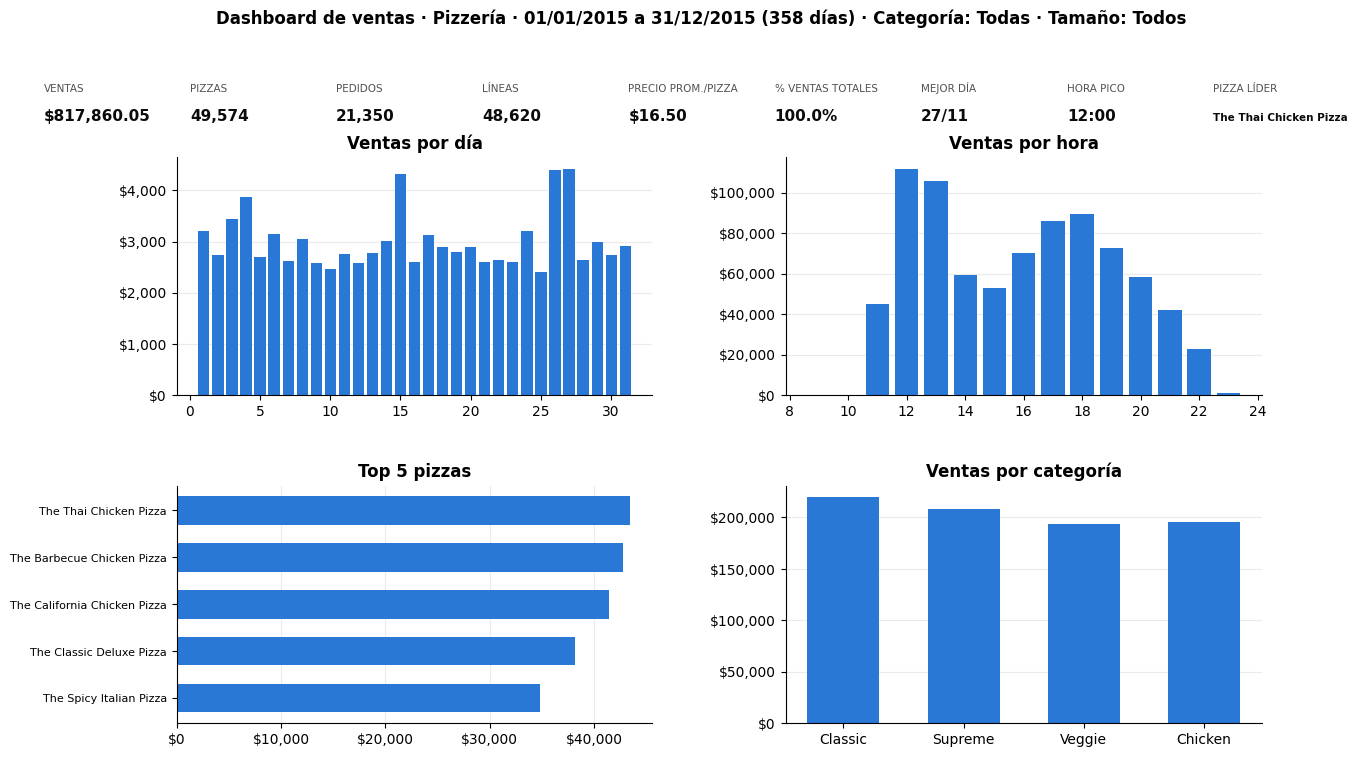

In [49]:
GB.dashboard(titulo="Dashboard de ventas · Pizzería")

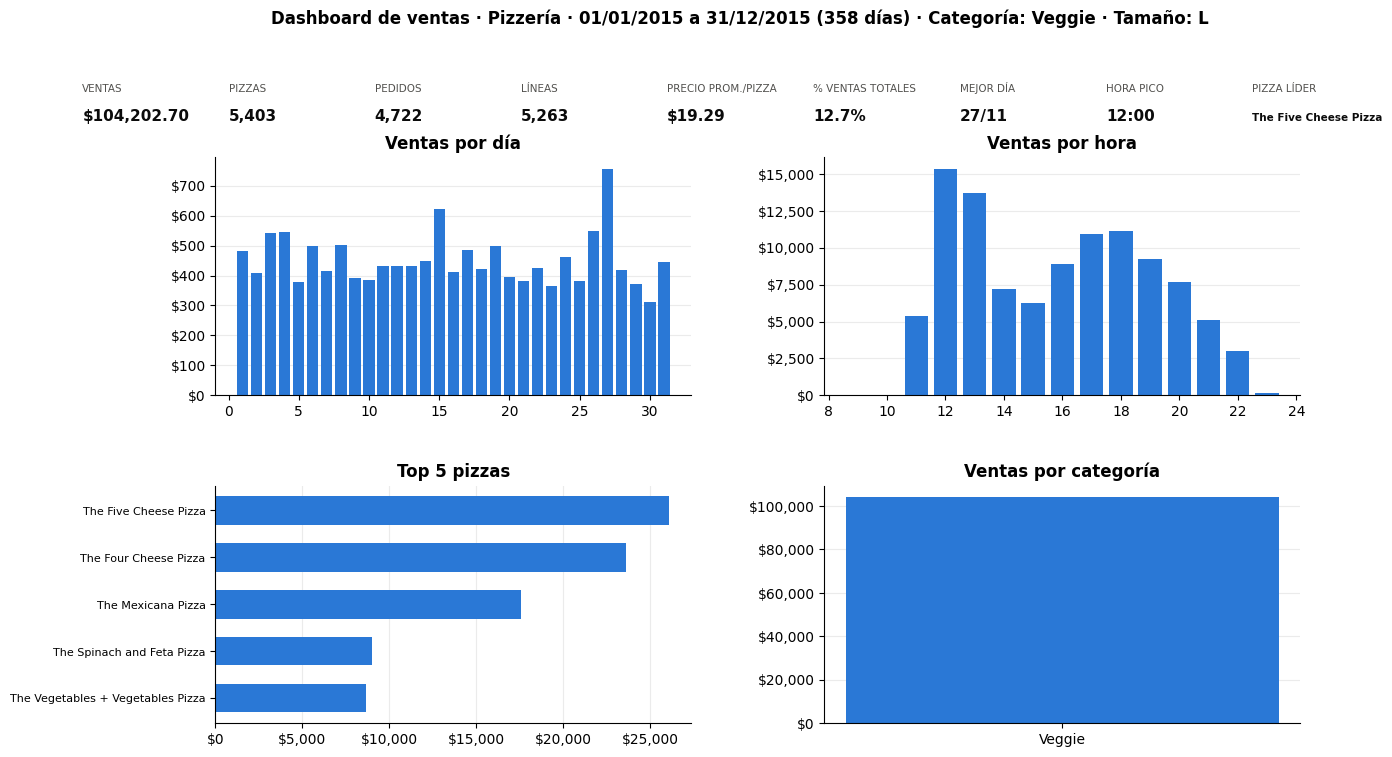

In [50]:
GB.dashboard(categoria="Veggie", tamano="L", titulo="Dashboard de ventas · Pizzería")